<a href="https://colab.research.google.com/github/fida22/nighttime-flare-removal/blob/main/notebooks/01_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 01 - Dataset & Preprocessing

**Objective:** Prepare and verify the Flare7K++ dataset for supervised nighttime lens flare removal.

This notebook covers:
- Dataset download and extraction
- Official Flare7K flare generation pipeline
- Generated input–target pair visualization and validation
- Training and validation split
- Image preprocessing and DataLoader setup

**Expected output:** Verified training and validation DataLoaders containing paired 256 × 256 RGB images.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys, yaml
REPO = "/content/nighttime-flare-removal"
if not os.path.exists(REPO):
    !git clone https://github.com/fida22/nighttime-flare-removal.git {REPO}   # <-- replace USERNAME
%cd {REPO}
!git pull
!pip -q install pyyaml scikit-image tqdm
sys.path.insert(0, REPO)
cfg = yaml.safe_load(open("configs/default.yaml"))
cfg["project"]["drive_root"] = "/content/drive/MyDrive/Nighttime_Flare_Removal_Colab"
import torch
print("CUDA:", torch.cuda.is_available())

Mounted at /content/drive
Cloning into '/content/nighttime-flare-removal'...
remote: Enumerating objects: 41, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 41 (delta 6), reused 35 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (41/41), 20.43 KiB | 6.81 MiB/s, done.
Resolving deltas: 100% (6/6), done.
/content/nighttime-flare-removal
Already up to date.
CUDA: True


In [ ]:

# ==========================================
# PROJECT DIRECTORY CONFIGURATION
# ==========================================

# Get the project directory from the configuration
PROJECT = cfg["project"]["drive_root"]

print("Project folder:", PROJECT)

# Create all required project directories
required_dirs = [
    "data/archives",
    "checkpoints/baseline",
    "checkpoints/improved",
    "results/metrics",
    "results/figures",
    "logs",
    "splits"
]

for folder in required_dirs:
    os.makedirs(os.path.join(PROJECT, folder), exist_ok=True)

print("\nProject directories created/verified!")

# Verify archive directory
print("\nArchive files:")
print(os.listdir(os.path.join(PROJECT, "data/archives")))


Project folder: /content/drive/MyDrive/Nighttime_Flare_Removal_Colab

Project directories created/verified!

Archive files:
['Flare7K++.zip', 'Background.zip']


In [ ]:
import gdown
import os

ARCHIVE_DIR = "/content/drive/MyDrive/Nighttime_Flare_Removal_Colab/data/archives"

file_id = "1PPXWxn7gYvqwHX301SuWmjI7IUUtqxab"

output = os.path.join(ARCHIVE_DIR, "Flare7K++.zip")

gdown.download(
    f"https://drive.google.com/uc?id={file_id}",
    output,
    quiet=False
)

Downloading...
From (original): https://drive.google.com/uc?id=1PPXWxn7gYvqwHX301SuWmjI7IUUtqxab
From (redirected): https://drive.google.com/uc?id=1PPXWxn7gYvqwHX301SuWmjI7IUUtqxab&confirm=t&uuid=394bfc22-dc25-4e6d-ad87-3b9149e1aee1
To: /content/drive/MyDrive/Nighttime_Flare_Removal_Colab/data/archives/Flare7K++.zip
100%|██████████| 3.99G/3.99G [00:50<00:00, 78.6MB/s]


'/content/drive/MyDrive/Nighttime_Flare_Removal_Colab/data/archives/Flare7K++.zip'

In [ ]:
import gdown
import os

ARCHIVE_DIR = "/content/drive/MyDrive/Nighttime_Flare_Removal_Colab/data/archives"

os.makedirs(ARCHIVE_DIR, exist_ok=True)

file_id = "1GNFGWfUbgXfELx5fZtjTjU2qqWnEa-Lr"

output = os.path.join(ARCHIVE_DIR, "Background.zip")

gdown.download(
    f"https://drive.google.com/uc?id={file_id}",
    output,
    quiet=False
)

Downloading...
From (original): https://drive.google.com/uc?id=1GNFGWfUbgXfELx5fZtjTjU2qqWnEa-Lr
From (redirected): https://drive.google.com/uc?id=1GNFGWfUbgXfELx5fZtjTjU2qqWnEa-Lr&confirm=t&uuid=5ef4aa72-5f0a-4618-8ebd-dc42f5ce4562
To: /content/drive/MyDrive/Nighttime_Flare_Removal_Colab/data/archives/Background.zip
100%|██████████| 1.20G/1.20G [00:23<00:00, 50.7MB/s]


'/content/drive/MyDrive/Nighttime_Flare_Removal_Colab/data/archives/Background.zip'

In [ ]:
for f in os.listdir(ARCHIVE_DIR):
    path = os.path.join(ARCHIVE_DIR, f)
    print(f, "—", round(os.path.getsize(path) / (1024**3), 2), "GB")

Background.zip — 1.12 GB
Flare7K++.zip — 3.72 GB


## 2. Dataset Download & Extraction

Download the Flare7K++ dataset and Flickr24K background images. Inspect the archive contents, extract them, and verify the resulting directory structure.

In [ ]:
%cd /content
!git clone https://github.com/ykdai/Flare7K.git
!mkdir -p /content/flare_data
# Replace with the EXACT filenames printed above:
# !unzip -q "{PROJECT}/data/archives/FLARE_ARCHIVE.zip" -d /content/flare_data/
# !unzip -q "{PROJECT}/data/archives/BACKGROUND_ARCHIVE.zip" -d /content/flare_data/
!find /content/flare_data -maxdepth 4 -type d | head -100

/content
fatal: destination path 'Flare7K' already exists and is not an empty directory.
/content/flare_data
/content/flare_data/Flare7Kpp
/content/flare_data/Flare7Kpp/test_data
/content/flare_data/Flare7Kpp/test_data/synthetic
/content/flare_data/Flare7Kpp/test_data/synthetic/gt
/content/flare_data/Flare7Kpp/test_data/synthetic/mask
/content/flare_data/Flare7Kpp/test_data/synthetic/input
/content/flare_data/Flare7Kpp/test_data/real
/content/flare_data/Flare7Kpp/test_data/real/gt
/content/flare_data/Flare7Kpp/test_data/real/mask
/content/flare_data/Flare7Kpp/test_data/real/input
/content/flare_data/Flare7Kpp/Flare-R
/content/flare_data/Flare7Kpp/Flare-R/Compound_Flare
/content/flare_data/Flare7Kpp/Flare-R/Light_Source
/content/flare_data/Flare7Kpp/Flare7K
/content/flare_data/Flare7Kpp/Flare7K/Reflective_Flare
/content/flare_data/Flare7Kpp/Flare7K/Scattering_Flare
/content/flare_data/Flare7Kpp/Flare7K/Scattering_Flare/Glare_with_shimmer
/content/flare_data/Flare7Kpp/Flare7K/Scattering_

In [ ]:
import zipfile
import os

ARCHIVE_DIR = "/content/drive/MyDrive/Nighttime_Flare_Removal_Colab/data/archives"

zip_path = os.path.join(ARCHIVE_DIR, "Flare7K++.zip")

with zipfile.ZipFile(zip_path, 'r') as z:
    print("Flare7K++ archive contents:")
    for name in z.namelist()[:40]:
        print(name)

Flare7K++ archive contents:
Flare7Kpp/
Flare7Kpp/Flare-R/
Flare7Kpp/Flare-R/Compound_Flare/
Flare7Kpp/Flare-R/Compound_Flare/000000.png
Flare7Kpp/Flare-R/Compound_Flare/000001.png
Flare7Kpp/Flare-R/Compound_Flare/000002.png
Flare7Kpp/Flare-R/Compound_Flare/000003.png
Flare7Kpp/Flare-R/Compound_Flare/000004.png
Flare7Kpp/Flare-R/Compound_Flare/000005.png
Flare7Kpp/Flare-R/Compound_Flare/000006.png
Flare7Kpp/Flare-R/Compound_Flare/000007.png
Flare7Kpp/Flare-R/Compound_Flare/000008.png
Flare7Kpp/Flare-R/Compound_Flare/000009.png
Flare7Kpp/Flare-R/Compound_Flare/000010.png
Flare7Kpp/Flare-R/Compound_Flare/000011.png
Flare7Kpp/Flare-R/Compound_Flare/000012.png
Flare7Kpp/Flare-R/Compound_Flare/000013.png
Flare7Kpp/Flare-R/Compound_Flare/000014.png
Flare7Kpp/Flare-R/Compound_Flare/000015.png
Flare7Kpp/Flare-R/Compound_Flare/000016.png
Flare7Kpp/Flare-R/Compound_Flare/000017.png
Flare7Kpp/Flare-R/Compound_Flare/000018.png
Flare7Kpp/Flare-R/Compound_Flare/000019.png
Flare7Kpp/Flare-R/Compound_F

In [ ]:
import zipfile
import os

ARCHIVE_DIR = "/content/drive/MyDrive/Nighttime_Flare_Removal_Colab/data/archives"

zip_path = os.path.join(ARCHIVE_DIR, "Background.zip")

with zipfile.ZipFile(zip_path, 'r') as z:
    print("Background archive contents:")
    for name in z.namelist()[:40]:
        print(name)

Background archive contents:
Flickr24K/
Flickr24K/100.jpg
Flickr24K/1000.jpg
Flickr24K/10001.jpg
Flickr24K/10002.jpg
Flickr24K/10005.jpg
Flickr24K/10007.jpg
Flickr24K/10008.jpg
Flickr24K/10009.jpg
Flickr24K/10010.jpg
Flickr24K/10015.jpg
Flickr24K/10016.jpg
Flickr24K/10017.jpg
Flickr24K/10018.jpg
Flickr24K/10019.jpg
Flickr24K/10020.jpg
Flickr24K/10021.jpg
Flickr24K/10022.jpg
Flickr24K/10025.jpg
Flickr24K/10026.jpg
Flickr24K/10027.jpg
Flickr24K/10028.jpg
Flickr24K/10029.jpg
Flickr24K/10030.jpg
Flickr24K/10031.jpg
Flickr24K/10032.jpg
Flickr24K/10037.jpg
Flickr24K/10038.jpg
Flickr24K/10039.jpg
Flickr24K/10040.jpg
Flickr24K/10043.jpg
Flickr24K/10044.jpg
Flickr24K/10045.jpg
Flickr24K/10046.jpg
Flickr24K/10047.jpg
Flickr24K/10048.jpg
Flickr24K/10049.jpg
Flickr24K/1005.jpg
Flickr24K/10050.jpg
Flickr24K/10051.jpg


In [ ]:
import zipfile
import os

ARCHIVE_DIR = "/content/drive/MyDrive/Nighttime_Flare_Removal_Colab/data/archives"
EXTRACT_DIR = "/content/flare_data"

os.makedirs(EXTRACT_DIR, exist_ok=True)

# Extract Flare7K++
with zipfile.ZipFile(os.path.join(ARCHIVE_DIR, "Flare7K++.zip")) as z:
    z.extractall(EXTRACT_DIR)

print("Flare7K++ extracted!")

# Extract Background images
with zipfile.ZipFile(os.path.join(ARCHIVE_DIR, "Background.zip")) as z:
    z.extractall(EXTRACT_DIR)

print("Background images extracted!")

Flare7K++ extracted!
Background images extracted!


In [ ]:
!find /content/flare_data -maxdepth 4 -type d

/content/flare_data
/content/flare_data/Flickr24K
/content/flare_data/Flare7Kpp
/content/flare_data/Flare7Kpp/test_data
/content/flare_data/Flare7Kpp/test_data/synthetic
/content/flare_data/Flare7Kpp/test_data/synthetic/input
/content/flare_data/Flare7Kpp/test_data/synthetic/gt
/content/flare_data/Flare7Kpp/test_data/synthetic/mask
/content/flare_data/Flare7Kpp/test_data/real
/content/flare_data/Flare7Kpp/test_data/real/input
/content/flare_data/Flare7Kpp/test_data/real/gt
/content/flare_data/Flare7Kpp/test_data/real/mask
/content/flare_data/Flare7Kpp/Flare7K
/content/flare_data/Flare7Kpp/Flare7K/Reflective_Flare
/content/flare_data/Flare7Kpp/Flare7K/Scattering_Flare
/content/flare_data/Flare7Kpp/Flare7K/Scattering_Flare/Core
/content/flare_data/Flare7Kpp/Flare7K/Scattering_Flare/Compound_Flare
/content/flare_data/Flare7Kpp/Flare7K/Scattering_Flare/Light_Source
/content/flare_data/Flare7Kpp/Flare7K/Scattering_Flare/Streak
/content/flare_data/Flare7Kpp/Flare7K/Scattering_Flare/Glare_wit


## 4. Dataset Structure & Verification

Inspect the extracted dataset directory structure, image counts, and official dataset documentation.

The official Flare7K loader will be used later to generate flare-corrupted images directly from clean backgrounds.


In [ ]:
!cat /content/Flare7K/docs/DATA_NOTES.md

cat: /content/Flare7K/docs/DATA_NOTES.md: No such file or directory


In [ ]:
import os

ROOT = "/content/flare_data"

paths = {
    "Background": os.path.join(ROOT, "Flickr24K"),
    "Scattering": os.path.join(
        ROOT, "Flare7Kpp", "Flare7K", "Scattering_Flare", "Compound_Flare"
    ),
    "Reflective": os.path.join(
        ROOT, "Flare7Kpp", "Flare7K", "Reflective_Flare"
    ),
    "Synthetic test input": os.path.join(
        ROOT, "Flare7Kpp", "test_data", "synthetic", "input"
    ),
    "Synthetic test target": os.path.join(
        ROOT, "Flare7Kpp", "test_data", "synthetic", "gt"
    ),
    "Real test input": os.path.join(
        ROOT, "Flare7Kpp", "test_data", "real", "input"
    ),
    "Real test target": os.path.join(
        ROOT, "Flare7Kpp", "test_data", "real", "gt"
    )
}

for name, path in paths.items():
    print(f"{name}: {os.path.exists(path)}")
    if os.path.exists(path):
        print("  Images:", len(os.listdir(path)))

Background: True
  Images: 23949
Scattering: True
  Images: 5000
Reflective: True
  Images: 2000
Synthetic test input: True
  Images: 100
Synthetic test target: True
  Images: 100
Real test input: True
  Images: 100
Real test target: True
  Images: 100


## 5. Official Flare7K Generation Pipeline

Use the official Flare7K data loader and transformations to generate flare-corrupted images from clean background images.

The loader returns:
- `base_img`: Clean background (target)
- `flare_img`: Generated flare component
- `merge_img`: Flare-corrupted image (input)
- `flare_mask`: Flare mask

In [ ]:
import os
import sys
import torch
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Official repository
REPO = "/content/Flare7K"

if REPO not in sys.path:
    sys.path.insert(0, REPO)

from data_loader import Flare_Image_Loader

# Dataset paths
BACKGROUND = "/content/flare_data/Flickr24K"

SCATTERING = (
    "/content/flare_data/Flare7Kpp/Flare7K/"
    "Scattering_Flare/Compound_Flare"
)

REFLECTIVE = (
    "/content/flare_data/Flare7Kpp/Flare7K/"
    "Reflective_Flare"
)

# Official transforms from generate_flare.ipynb
transform_base = transforms.Compose([
    transforms.RandomCrop(
        (512, 512),
        pad_if_needed=True,
        padding_mode="reflect"
    ),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip()
])

transform_flare = transforms.Compose([
    transforms.RandomAffine(
        degrees=(0, 360),
        scale=(0.8, 1.5),
        translate=(300/1440, 300/1440),
        shear=(-20, 20)
    ),
    transforms.CenterCrop((512, 512)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip()
])

# Initialize official loader
flare_image_loader = Flare_Image_Loader(
    BACKGROUND,
    transform_base,
    transform_flare
)

flare_image_loader.load_scattering_flare(
    "Flare7K",
    SCATTERING
)

flare_image_loader.load_reflective_flare(
    "Flare7K",
    REFLECTIVE
)

print("Background images:", len(flare_image_loader))
print("Scattering images:", len(flare_image_loader.flare_list))
print("Reflective images:", len(flare_image_loader.reflective_list))

Base Image Loaded with examples: 23949
Scattering Flare Image: Flare7K  is loaded successfully with examples 5000
Now we have 5000 scattering flare images
Reflective Flare Image: Flare7K  is loaded successfully with examples 2000
Now we have 2000 refelctive flare images
Background images: 23949
Scattering images: 5000
Reflective images: 2000


## 6. Generated Pair Visualization & Validation

Visualize generated clean targets, flare components and flare-corrupted inputs.

Inspect five sample pairs visually, then validate twenty randomly selected pairs for matching dimensions, RGB channels, valid pixel ranges and finite values.

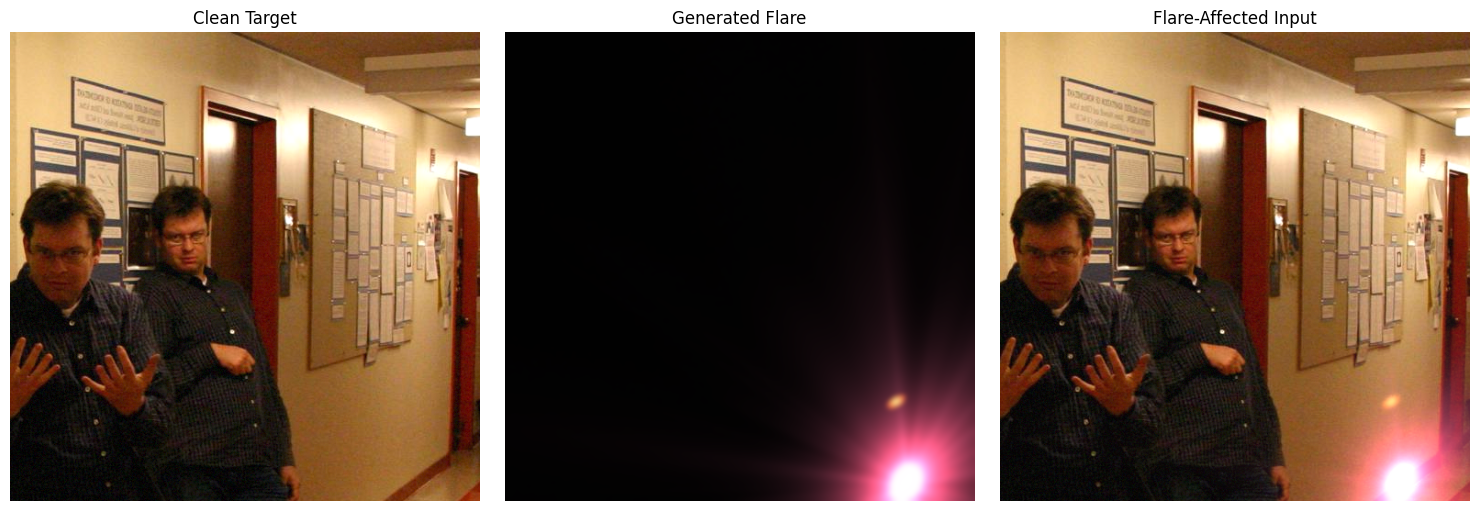

Pair 1 verified


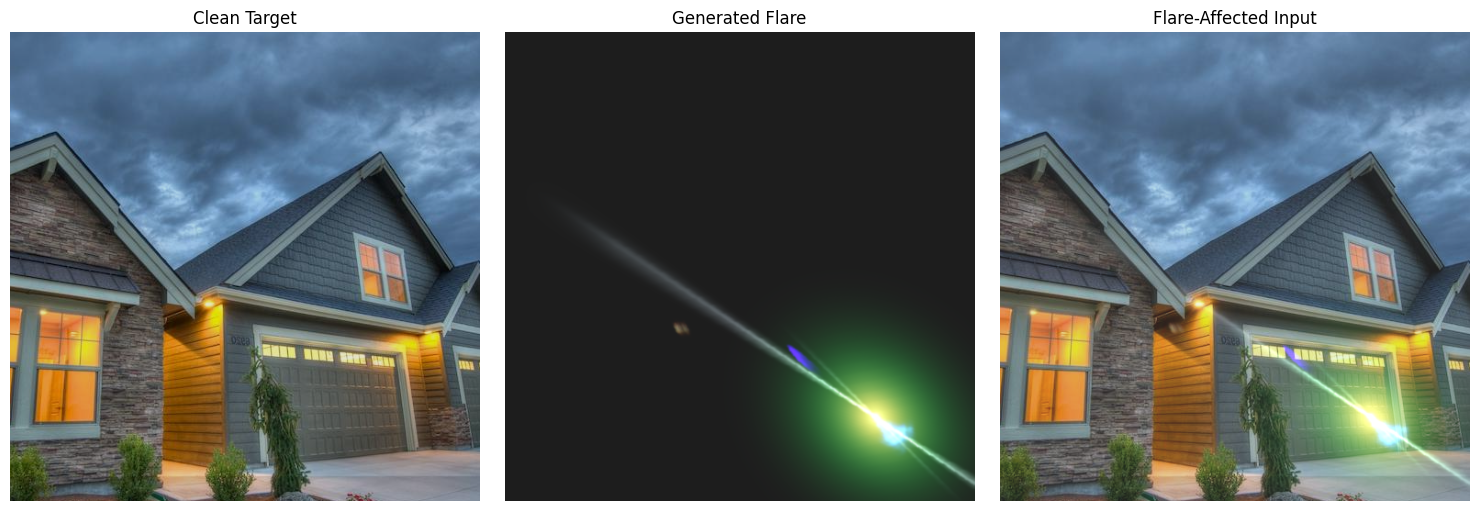

Pair 2 verified


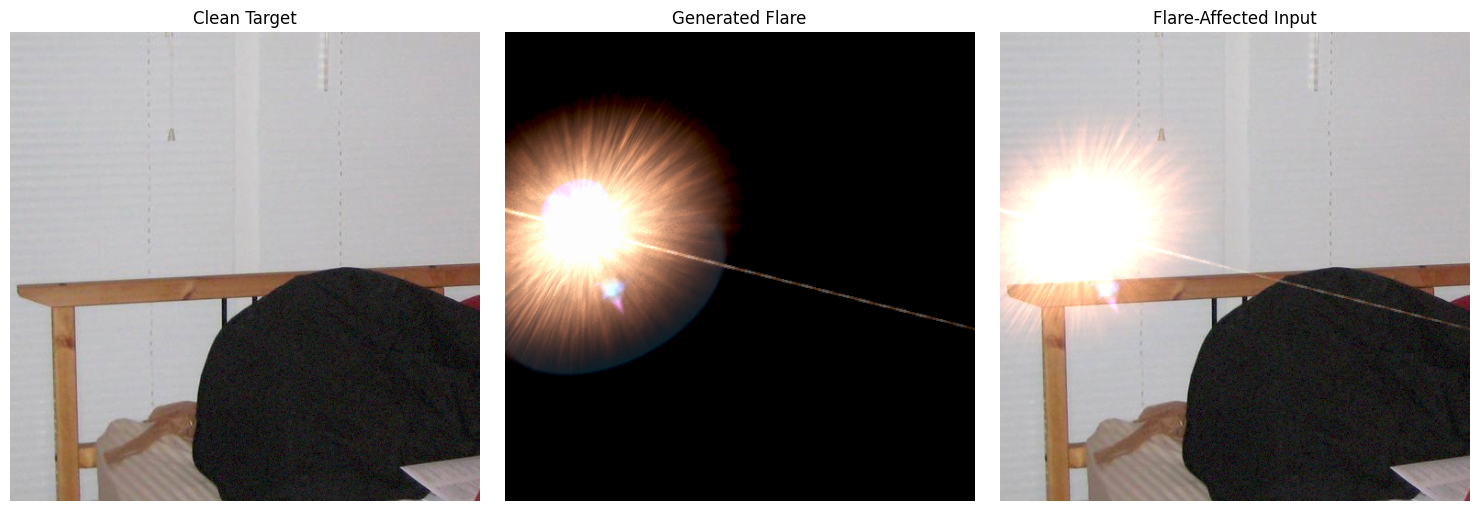

Pair 3 verified


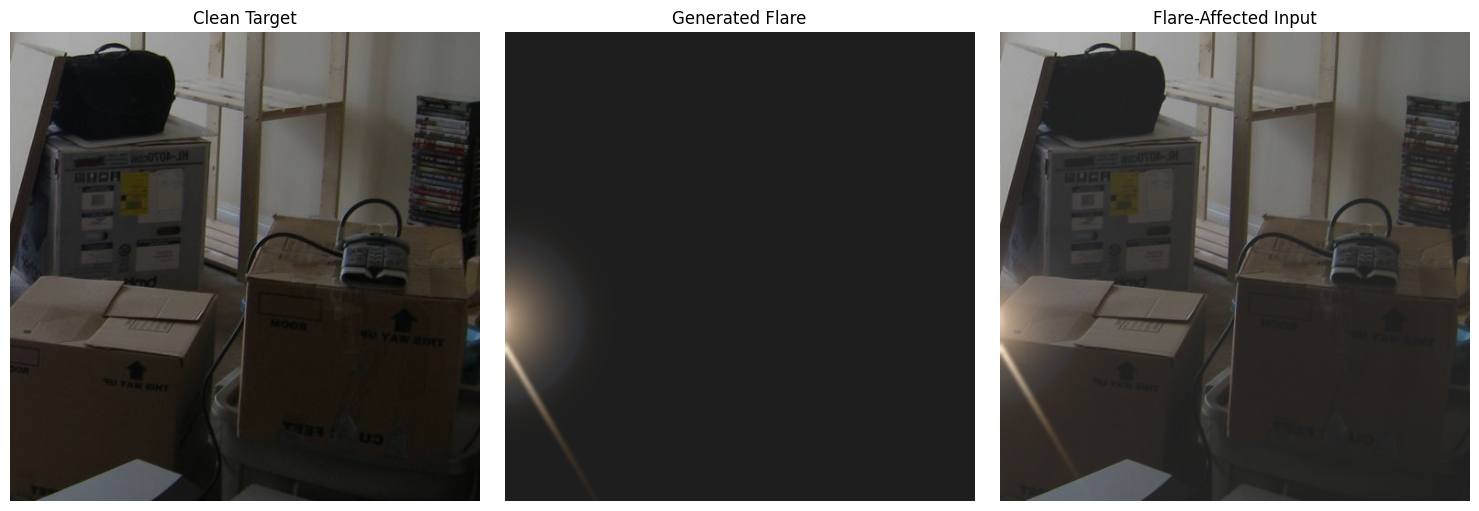

Pair 4 verified


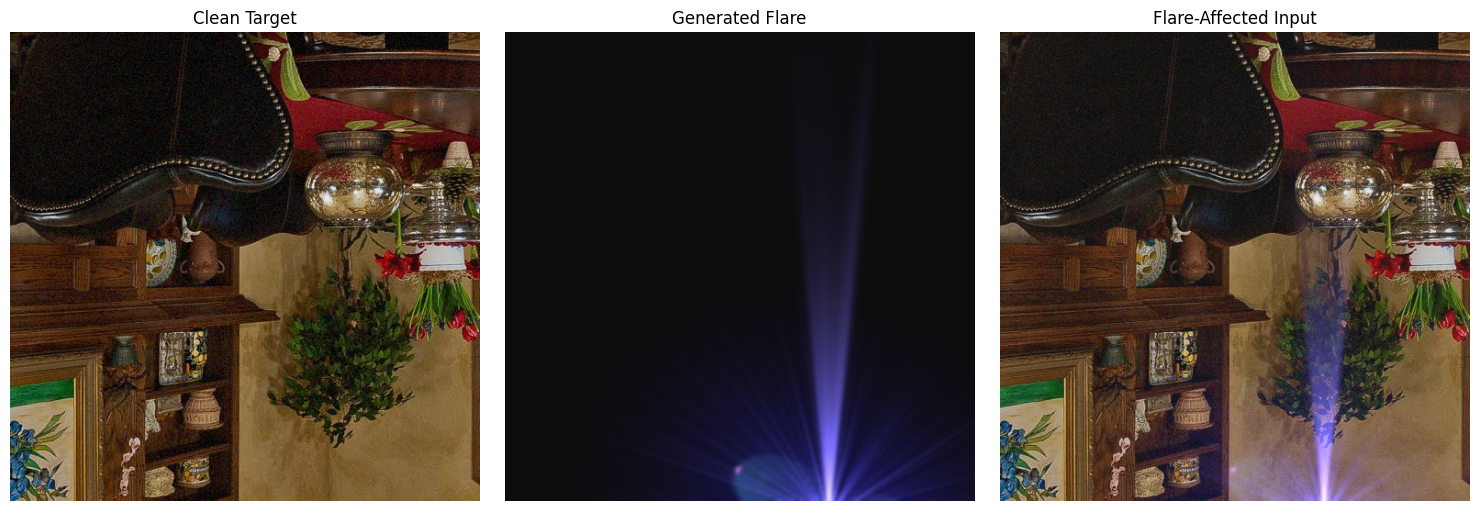

Pair 5 verified


In [ ]:
import matplotlib.pyplot as plt

for i in range(5):

    base_img, flare_img, merge_img, flare_mask = flare_image_loader[i]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    images = [
        (base_img, "Clean Target"),
        (flare_img, "Generated Flare"),
        (merge_img, "Flare-Affected Input")
    ]

    for ax, (img, title) in zip(axes, images):
        ax.imshow(img.permute(1, 2, 0).numpy())
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print(f"Pair {i+1} verified")

In [ ]:
import torch
import numpy as np

print("Checking 20 randomly selected pairs...\n")
import random

indices = random.sample(
    range(len(flare_image_loader)),
    min(20, len(flare_image_loader))
)
for idx in indices:

    base_img, flare_img, merge_img, flare_mask = flare_image_loader[idx]

    assert base_img.shape == merge_img.shape, \
        f"Shape mismatch at {idx}"

    assert torch.isfinite(base_img).all()
    assert torch.isfinite(merge_img).all()

    assert base_img.min() >= 0 and base_img.max() <= 1
    assert merge_img.min() >= 0 and merge_img.max() <= 1

    assert base_img.shape[0] == 3, \
        f"Expected RGB at {idx}"

print("All 20 pairs passed validation!")

Checking 20 randomly selected pairs...

All 20 pairs passed validation!


In [ ]:
import torch

print("LOADER INFORMATION")
print("Type:", type(flare_image_loader))
print("Number of backgrounds:", len(flare_image_loader))

print("\nLOADER ATTRIBUTES")
for attr in ["data_list", "flare_list", "reflective_list"]:
    value = getattr(flare_image_loader, attr, None)

    if value is not None:
        print(f"{attr}: {len(value)} items")
    else:
        print(f"{attr}: Not available")


print("\nSAMPLE OUTPUT")

sample = flare_image_loader[0]

print("Number of returned values:", len(sample))

for i, item in enumerate(sample):
    if isinstance(item, torch.Tensor):
        print(
            f"Item {i}: Shape={item.shape}, "
            f"Dtype={item.dtype}, "
            f"Range=({item.min().item():.4f}, "
            f"{item.max().item():.4f})"
        )
    else:
        print(f"Item {i}: {type(item)}")

LOADER INFORMATION
Type: <class 'data_loader.Flare_Image_Loader'>
Number of backgrounds: 23949

LOADER ATTRIBUTES
data_list: 23949 items
flare_list: 5000 items
reflective_list: 2000 items

SAMPLE OUTPUT
Number of returned values: 4
Item 0: Shape=torch.Size([3, 512, 512]), Dtype=torch.float32, Range=(0.0000, 0.9860)
Item 1: Shape=torch.Size([3, 512, 512]), Dtype=torch.float32, Range=(0.0000, 0.9989)
Item 2: Shape=torch.Size([3, 512, 512]), Dtype=torch.float32, Range=(0.0000, 1.0000)
Item 3: <class 'float'>


## 7. Train–Validation Split

Split the generated background dataset into 80% training and 20% validation subsets using a fixed random seed.

In [ ]:
import torch
import random
from torch.utils.data import Dataset, DataLoader, random_split

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
random.seed(SEED)

# 80:20 split
total_size = len(flare_image_loader)

train_size = int(0.8 * total_size)
val_size = total_size - train_size

train_subset, val_subset = random_split(
    flare_image_loader,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

print("Dataset split completed")
print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))

Dataset split completed
Training samples: 19159
Validation samples: 4790


## 8. Image Preprocessing

Prepare paired input and target images for model training.

- Input: Flare-corrupted image
- Target: Clean background image
- Image size: 256 × 256
- Training: Random paired crops and identical horizontal/vertical flips
- Validation: Center crop without additional random augmentation

In [ ]:
import numpy as np
import torch
import random
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset


class FlareDataset(Dataset):

    def __init__(self, subset, training=True):
        self.subset = subset
        self.training = training

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):

        # Get official loader output
        if self.training:
            base_img, flare_img, merge_img, flare_mask = self.subset[idx]

        else:
            # Save random states
            python_state = random.getstate()
            numpy_state = np.random.get_state()
            torch_state = torch.get_rng_state()

            try:
                # Use a fixed seed for each validation sample
                seed = 42000 + idx

                random.seed(seed)
                np.random.seed(seed)
                torch.manual_seed(seed)

                base_img, flare_img, merge_img, flare_mask = self.subset[idx]

            finally:
                # Restore random states
                random.setstate(python_state)
                np.random.set_state(numpy_state)
                torch.set_rng_state(torch_state)

        # Input = flare-affected image
        # Target = clean background
        input_img = merge_img
        target_img = base_img

        if self.training:

            # Random paired crop (256 x 256)
            i, j = torch.randint(0, 257, (2,)).tolist()

            input_img = TF.crop(input_img, i, j, 256, 256)
            target_img = TF.crop(target_img, i, j, 256, 256)

            # Identical horizontal flip
            if random.random() > 0.5:
                input_img = TF.hflip(input_img)
                target_img = TF.hflip(target_img)

            # Identical vertical flip
            if random.random() > 0.5:
                input_img = TF.vflip(input_img)
                target_img = TF.vflip(target_img)

        else:

            # Deterministic center crop for validation
            input_img = TF.center_crop(input_img, [256, 256])
            target_img = TF.center_crop(target_img, [256, 256])

        return {
            "input": input_img.float(),
            "target": target_img.float()
        }


# Create datasets
train_dataset = FlareDataset(train_subset, training=True)
val_dataset = FlareDataset(val_subset, training=False)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Preprocessing datasets created successfully!")

Training dataset: 19159
Validation dataset: 4790
Preprocessing datasets created successfully!


## 9. DataLoader Configuration

Create PyTorch DataLoaders for training and validation using a batch size of 4.

In [ ]:
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 4790
Validation batches: 1198


## 10. Final Data Pipeline Verification

Retrieve one training batch and verify:
- Input and target tensor dimensions
- Pixel value ranges
- Absence of NaN or infinite values

Expected tensor shape: `(4, 3, 256, 256)`.

In [ ]:
batch = next(iter(train_loader))

print("INPUT:")
print("Shape:", batch["input"].shape)
print("Range:",
      batch["input"].min().item(),
      batch["input"].max().item())

print("\nTARGET:")
print("Shape:", batch["target"].shape)
print("Range:",
      batch["target"].min().item(),
      batch["target"].max().item())

assert batch["input"].shape == (4, 3, 256, 256)
assert batch["target"].shape == (4, 3, 256, 256)

assert torch.isfinite(batch["input"]).all()
assert torch.isfinite(batch["target"]).all()

print("\nAll batch checks passed!")

INPUT:
Shape: torch.Size([4, 3, 256, 256])
Range: 0.0 1.0

TARGET:
Shape: torch.Size([4, 3, 256, 256])
Range: 0.0 0.9839816689491272

All batch checks passed!



### Validation Reproducibility Check

Verify that repeated access to the same validation sample produces identical input and target images.

This ensures that validation results are consistent across repeated evaluations.


In [ ]:
sample1 = val_dataset[0]
sample2 = val_dataset[0]

print("Input identical:",
      torch.equal(sample1["input"], sample2["input"]))

print("Target identical:",
      torch.equal(sample1["target"], sample2["target"]))

Input identical: True
Target identical: True
